# Inferring liquidity from observed price ranges

This Julia notebook follows the same experiment, equations, sample sizes, parameters, and decision rules as its Python counterpart. Random experiments use the displayed integer seeds with Julia’s `Xoshiro` generator, so their realized samples differ from NumPy. Public observations use the same stated data sources. Figures use the requested dark theme, and Julia outputs are saved under `outputs/julia`. The finite-sample study draws its 1,440 child seeds from `Xoshiro(20260926)` and saves every Gaussian innovation, observed trade side, and resulting OHLC bar so the calculation can be repeated. The published equation is compared with the current library calculation.

The relative effective spread measures twice the signed distance between a transaction price and an unobserved fair price:

$$
S_t=\frac{2D_t(P_t-\widetilde P_t)}{\widetilde P_t},
\qquad D_t\in\{-1,1\}.
$$

Here, $S_t$ is the proportional effective spread for trade $t$; $P_t$ is the observed transaction price. $\widetilde P_t$ is the unobserved fair price; $D_t=1$ for a buyer-initiated trade and $D_t=-1$ for a seller-initiated trade.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("11_market_microstructure");
using CSV, Printf
using RiskLabAI.Features: alpha_estimates,bekker_parkinson_volatility_estimates,beta_estimates,corwin_schultz_estimator,edge_estimator,gamma_estimates,sigma_estimates
raw = load_binance()
data_path = dataset_path("binance_btcusdt")
@assert isfile(data_path)
minute = select(raw,:time,"Open"=>:open,"High"=>:high,"Low"=>:low,:close,:volume,:quote_volume,:trades)

function make_bars(period)
    return combine(groupby(transform(minute,:time=>(time->floor.(time,period))=>:time),:time;sort=true),:open=>first=>:open,:high=>maximum=>:high,:low=>minimum=>:low,:close=>last=>:close,:volume=>sum=>:volume,:quote_volume=>sum=>:quote_volume,:trades=>sum=>:trades)
end

function rolling_mean(values,window)
    result = fill(NaN,length(values))
    for ending in window:length(values)
        sample = values[ending-window+1:ending]
        all(isfinite,sample) && (result[ending]=mean(sample))
    end
    return result
end

function calendar_ticks(times;step=Day(6))
    ticks = collect(DateTime(Date(first(times))):step:DateTime(Date(last(times))))
    return Dates.value.(ticks),Dates.format.(ticks,dateformat"mm-dd")
end

function spread_values(sample)
    magnitude = edge_estimator(sample.open,sample.high,sample.low,sample.close)
    signed = edge_estimator(sample.open,sample.high,sample.low,sample.close;sign=true)
    cs = mean(filter(isfinite,corwin_schultz_estimator(sample.high,sample.low,1)))
    return (magnitude=magnitude,zero_floor=max(signed,0.),signed=signed,cs=cs)
end

bars_15 = make_bars(Minute(15));


## Building range-based liquidity measures

9×2 DataFrame
 Row │ Field                Value
     │ String               String
─────┼────────────────────────────────────────────────────────
   1 │ Archive              BTCUSDT-1m-2021-01.zip
   2 │ Provider             Binance Data Vision
   3 │ Market               BTCUSDT spot
   4 │ Interval             One minute
   5 │ Start                2021-01-01T00:00:00
   6 │ End                  2021-01-31T23:59:00
   7 │ One-minute rows      44,640
   8 │ Fifteen-minute bars  2,976

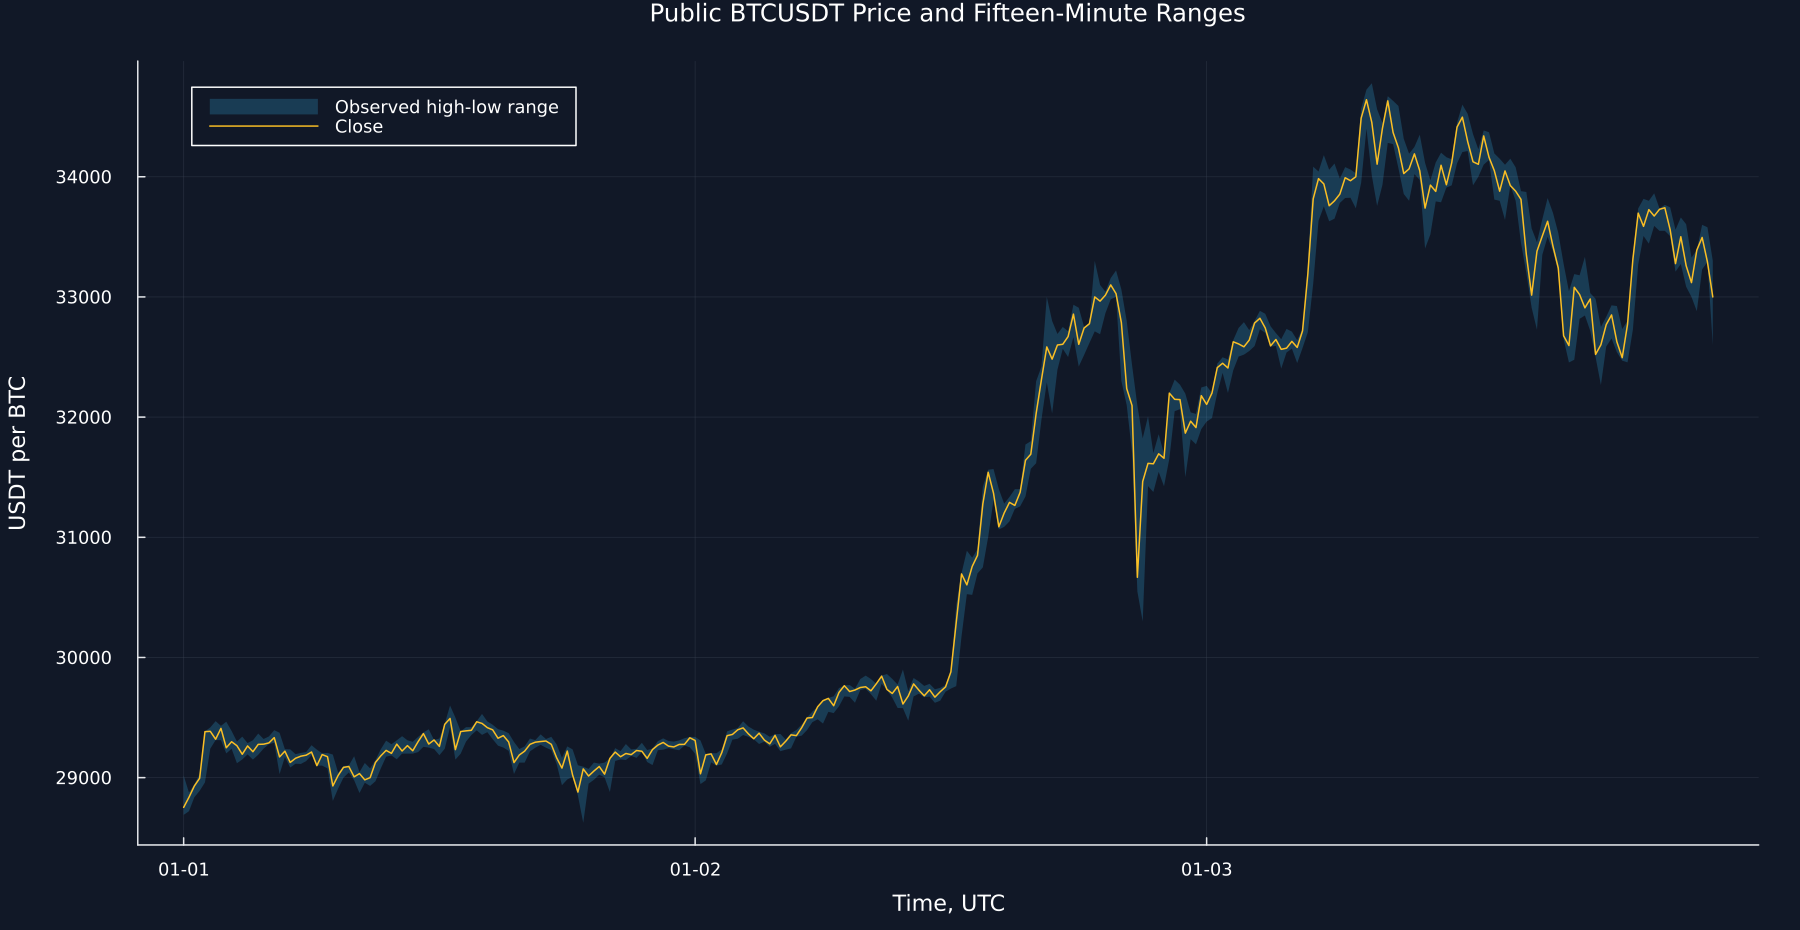

In [2]:
data_provenance = DataFrame("Field"=>["Archive","Provider","Market","Interval","Start","End","One-minute rows","Fifteen-minute bars"],"Value"=>["BTCUSDT-1m-2021-01.zip","Binance Data Vision","BTCUSDT spot","One minute",string(first(minute.time)),string(last(minute.time)),"44,640","2,976"])
save_table(data_provenance,paths,"data_provenance";caption="Public observations used in Chapter 10.",label="tab:chapter10-data-provenance")
public_window = bars_15[1:96*3,:]
figure = plot(public_window.time,public_window.low;fillrange=public_window.high,fillalpha=.22,linealpha=0,color=palette.cyan,label="Observed high-low range",title="Public BTCUSDT Price and Fifteen-Minute Ranges",xlabel="Time, UTC",ylabel="USDT per BTC",xticks=calendar_ticks(public_window.time;step=Day(1)),legend=:topleft,size=(1200,620))
plot!(figure,public_window.time,public_window.close;color=palette.amber,linewidth=1,label="Close")
save_figure(figure,paths,"public_price_ranges")
save_data(bars_15,paths,"public_fifteen_minute_bars");


## Range-Based Volatility

The logarithmic high-low range records the movement inside a bar, and the Parkinson calculation converts squared ranges into a variance estimate:

$$
R_t^{HL}=\log\!\left(\frac{H_t}{L_t}\right),
\qquad
\widehat\sigma_{P,m}^{2}
=\frac{1}{4m\log 2}\sum_{t=1}^{m}\left(R_t^{HL}\right)^2.
$$

Here, $H_t$ and $L_t$ are the observed high and low in bar $t$; $R_t^{HL}$ is that bar's logarithmic range. $m$ is the number of bars in the estimate; $\widehat\sigma_{P,m}^{2}$ is range-based variance per bar; $\log$ is the natural logarithm.

The close-to-close calculation estimates variance from one observed close change per bar and provides a comparison for the range calculation:

$$
\widehat\sigma_{C,m}^{2}
=\frac{1}{m}\sum_{t=1}^{m}
\left(\log C_t-\log C_{t-1}\right)^2.
$$

Here, $C_t$ is the close in bar $t$; $m$ is the number of squared close changes. $\widehat\sigma_{C,m}^{2}$ is close-to-close variance per bar; $\log C_t-\log C_{t-1}$ is the logarithmic close return.

In [3]:
frequency_specification = [("One minute",Minute(1),1440),("Five minutes",Minute(5),288),("Fifteen minutes",Minute(15),96),("One hour",Hour(1),24),("One day",Day(1),1)]
frequency_rows = NamedTuple[]
frequency_bars = DataFrame()
for (name,period,bars_per_day) in frequency_specification
    current = make_bars(period)
    log_range = log.(current.high./current.low)
    close_return = diff(log.(current.close))
    range_daily = sqrt(mean(log_range.^2)*bars_per_day/(4log(2)))
    close_daily = sqrt(mean(close_return.^2)*bars_per_day)
    push!(frequency_rows,(name=name,bars=nrow(current),median_range=10000median(log_range),trades=mean(current.trades),range=range_daily,close=close_daily,ratio=range_daily/close_daily))
    append!(frequency_bars,hcat(DataFrame(frequency=fill(name,nrow(current))),current);cols=:union)
end
range_volatility_summary = DataFrame(frequency_rows)
rename!(range_volatility_summary,["Bar length","Bars","Median range, basis points","Mean trades per bar","Range volatility, daily","Close volatility, daily","Range to close ratio"])
save_table(range_volatility_summary,paths,"range_volatility_summary";caption="Observed ranges and two daily volatility calculations across bar lengths.",label="tab:chapter10-range-volatility-summary")
log_range_15 = log.(bars_15.high./bars_15.low)
quantile_values = transpose(hcat([quantile(values,[0,.1,.5,.9,1]) for values in [10000log_range_15,Float64.(bars_15.trades),bars_15.quote_volume./1e6]]...))
range_quantiles = hcat(DataFrame("Quantity"=>["Log range, basis points","Trades per bar","Quote volume, million USDT"]),DataFrame(quantile_values,["Minimum","10th percentile","Median","90th percentile","Maximum"]))
save_table(range_quantiles,paths,"range_quantiles";caption="Distribution of public fifteen-minute range and activity measurements.",label="tab:chapter10-range-quantiles")
save_data(frequency_bars,paths,"public_frequency_bars");


Row,Bar length,Bars,"Median range, basis points",Mean trades per bar,"Range volatility, daily","Close volatility, daily",Range to close ratio
,String,Int64,Float64,Float64,Float64,Float64,Float64
1,One minute,44640,21.2618,1651.38,0.0757952,0.0769504,0.984988
2,Five minutes,8928,50.7697,8256.9,0.0777062,0.0756873,1.02667
3,Fifteen minutes,2976,92.481,24770.7,0.0781142,0.0763915,1.02255
4,One hour,744,193.255,99082.8,0.0775232,0.0695884,1.11403
5,One day,31,1040.77,2.37799e6,0.0719128,0.0552639,1.30126


Row,Quantity,Minimum,10th percentile,Median,90th percentile,Maximum
,String,Float64,Float64,Float64,Float64,Float64
1,"Log range, basis points",18.3272,48.7121,92.481,187.59,1003.56
2,Trades per bar,5727.0,12915.5,21203.0,39295.0,196911.0
3,"Quote volume, million USDT",4.74255,15.7736,31.5104,72.2028,437.063


## Rolling Comparison

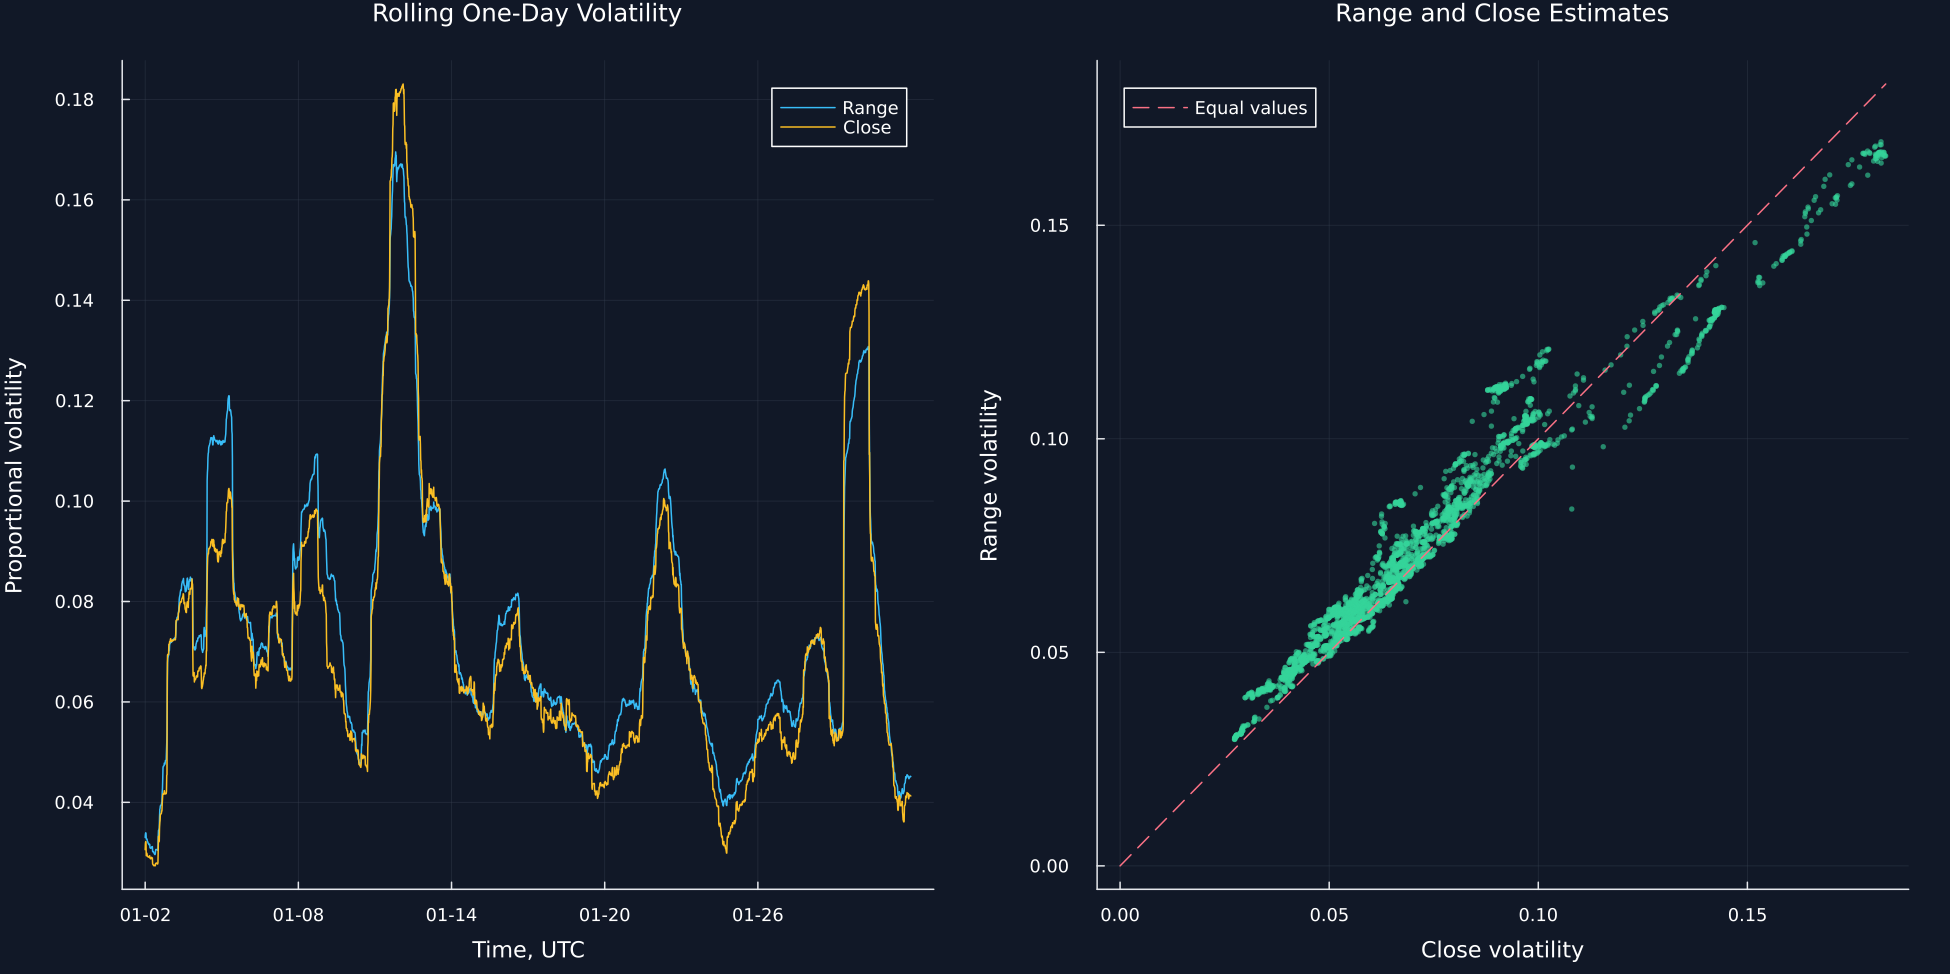

In [4]:
rolling_bars = 96
rolling_range_volatility = sqrt.(rolling_mean(log_range_15.^2,rolling_bars).*rolling_bars./(4log(2)))
rolling_close_volatility = sqrt.(rolling_mean([NaN;diff(log.(bars_15.close))].^2,rolling_bars).*rolling_bars)
valid = isfinite.(rolling_range_volatility).&isfinite.(rolling_close_volatility)
rolling_comparison = DataFrame(time=bars_15.time[valid],Range=rolling_range_volatility[valid],Close=rolling_close_volatility[valid])
p1 = plot(rolling_comparison.time,rolling_comparison.Range;color=palette.cyan,linewidth=1,label="Range",title="Rolling One-Day Volatility",xlabel="Time, UTC",ylabel="Proportional volatility",xticks=calendar_ticks(rolling_comparison.time),legend=:topright)
plot!(p1,rolling_comparison.time,rolling_comparison.Close;color=palette.amber,linewidth=1,label="Close")
p2 = scatter(rolling_comparison.Close,rolling_comparison.Range;markersize=2,markerstrokewidth=0,alpha=.6,color=palette.green,label=false,title="Range and Close Estimates",xlabel="Close volatility",ylabel="Range volatility",legend=:topleft)
diagonal_max = maximum(Matrix(rolling_comparison[:,2:3]))
plot!(p2,[0,diagonal_max],[0,diagonal_max];color=palette.rose,linewidth=1,linestyle=:dash,label="Equal values")
save_figure(plot(p1,p2;layout=(1,2),size=(1300,650)),paths,"range_volatility_comparison")
save_data(rolling_comparison,paths,"rolling_range_volatility");


## Tests

In [5]:
@assert nrow(minute)==44640
@assert nrow(bars_15)==2976
@assert first(minute.time)==DateTime(2021,1,1)
@assert last(minute.time)==DateTime(2021,1,31,23,59)
@assert issorted(bars_15.time)
@assert all(isfinite,Matrix(bars_15[:,2:end]))
@assert all(bars_15.high.>=max.(bars_15.open,bars_15.close))
@assert all(bars_15.low.<=min.(bars_15.open,bars_15.close))
@assert all(bars_15.high.>=bars_15.low)
@assert all(log_range_15.>=0)
@assert range_volatility_summary.Bars==[44640,8928,2976,744,31]
@assert issorted(range_volatility_summary[!,"Mean trades per bar"])
@assert all(Matrix(range_volatility_summary[:,["Range volatility, daily","Close volatility, daily"]]).>0)
@assert nrow(rolling_comparison)==nrow(bars_15)-rolling_bars
@assert all(Matrix(rolling_comparison[:,2:end]).>0)
@assert all(isfinite,Matrix(rolling_comparison[:,2:end]))
@assert isfile(joinpath(paths.figures,"public_price_ranges.pdf"))
@assert isfile(joinpath(paths.figures,"range_volatility_comparison.pdf"))
@assert isfile(joinpath(paths.tables,"data_provenance.tex"))
@assert isfile(joinpath(paths.tables,"range_volatility_summary.tex"))
@assert isfile(joinpath(paths.tables,"range_quantiles.tex"))
